Objetos detectados: 30
Ficha: centro (1214, 842), diametro 97.6 px -> 7.2 px/mm
Calibracion fina: factor 1.0130

  #   centro (px)      diametro   moneda
  --------------------------------------------
   1  (  1135,  1358)    22.07 mm   20cent
   2  (   552,  1272)    21.78 mm   20cent
   3  (  1454,  1230)    19.81 mm   10cent
   4  (  1731,  1199)    21.48 mm   5cent
   5  (  1254,  1140)    21.49 mm   5cent
   6  (  1006,  1122)    22.41 mm   20cent
   7  (   224,  1119)    21.29 mm   20cent
   8  (   638,   993)    22.14 mm   20cent
   9  (  1881,   954)    18.76 mm   2cent
  10  (  1586,   903)    23.62 mm   1euro
  11  (   530,   764)    19.53 mm   10cent
  12  (  1873,   723)    20.17 mm   10cent
  13  (   181,   731)    23.61 mm   50cent
  14  (   804,   706)    18.69 mm   2cent
  15  (  1379,   707)    21.29 mm   5cent
  16  (  1153,   563)    16.17 mm   1cent
  17  (  1586,   542)    21.32 mm   5cent
  18  (   548,   485)    25.60 mm   2euros
  19  (  1868,   468)    21.63 mm

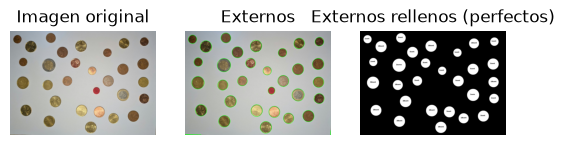

Imagen anotada guardada en: moneda5_resultado.jpg


In [1]:
# -*- coding: utf-8 -*-
"""
Recuento de monedas de euro usando una ficha de referencia de 13.5 mm.

    python monedas.py

La ficha se localiza por su color y da la escala; el fondo del papel se
estima por bloques y cada moneda se mide por su perfil radial. La
denominacion se elige por el diametro mas parecido dentro del mismo metal.
"""

import cv2
import numpy as np
import matplotlib.pyplot as plt

# --- parametros ------------------------------------------------------------
ruta = "moneda5.jpeg"
ficha_ideal_diametro = 13.5    # mm
umbral = 20                    # distancia de color objeto/fondo
tolerancia = 0.06              # error maximo al asignar la moneda
ficha_manual = None            # p. ej. (831, 1033) si la ficha no se detecta

# Diametro de cada moneda
monedas_diametro = {
    "1cent": 16.25, "2cent": 18.75, "5cent": 21.25,
    "10cent": 19.75, "20cent": 22.25, "50cent": 24.25,
    "1euro": 23.25, "2euros": 25.75
}
# Valor de cada moneda
valores = {
    "1cent": 0.01, "2cent": 0.02, "5cent": 0.05,
    "10cent": 0.10, "20cent": 0.20, "50cent": 0.50,
    "1euro": 1.00, "2euros": 2.00
}

# Color de cada moneda
metal = {
    "1cent": "cobre", "2cent": "cobre", "5cent": "cobre",
    "10cent": "oro", "20cent": "oro", "50cent": "oro",
    "1euro": "bimetal", "2euros": "bimetal"
}

# --- 1. imagen -------------------------------------------------------------
img = cv2.imread(ruta)
alto, ancho = img.shape[:2]
kernel = np.ones((5, 5), np.uint8)


def distancia_color(imagen, fondo):
    a = cv2.cvtColor(cv2.GaussianBlur(imagen, (5, 5), 0), cv2.COLOR_BGR2LAB).astype(float)
    b = cv2.cvtColor(np.clip(fondo, 0, 255).astype(np.uint8), cv2.COLOR_BGR2LAB).astype(float)
    return np.linalg.norm(a - b, axis=2)


# --- 2. fondo del papel ----------------------------------------------------
# Primer barrido con una mediana grande para saber que zona ocupan los objetos
pequena = cv2.resize(img, None, fx=0.12, fy=0.12, interpolation=cv2.INTER_AREA)
fondo = cv2.resize(cv2.medianBlur(pequena, 31), (ancho, alto), interpolation=cv2.INTER_LINEAR)
dif = distancia_color(img, fondo)
dif = np.maximum(dif - np.percentile(dif, 10), 0)
_, mascara = cv2.threshold(dif.astype(np.uint8), umbral, 255, cv2.THRESH_BINARY)
mascara = cv2.morphologyEx(mascara, cv2.MORPH_CLOSE, kernel, iterations=3)
excluir = cv2.dilate(mascara, np.ones((31, 31), np.uint8))

# Fondo definitivo: mediana de cada bloque del papel, ignorando los objetos
n = 20
bh, bw = max(1, alto // n), max(1, ancho // n)
fondo_peq = np.full((n, n, 3), np.nan, np.float32)
for i in range(n):
    for j in range(n):
        trozo = img[i * bh:(i + 1) * bh, j * bw:(j + 1) * bw]
        libres = trozo[excluir[i * bh:(i + 1) * bh, j * bw:(j + 1) * bw] == 0]
        if len(libres) > 0.25 * trozo[:, :, 0].size:
            fondo_peq[i, j] = np.median(libres, axis=0)
fondo_peq[np.isnan(fondo_peq[:, :, 0])] = np.median(img[excluir == 0].reshape(-1, 3), axis=0)
fondo = cv2.resize(fondo_peq, (ancho, alto), interpolation=cv2.INTER_CUBIC)
dif = distancia_color(img, fondo)

# --- 3. mascara y contornos externos ---------------------------------------
_, mascara = cv2.threshold(dif.astype(np.uint8), umbral, 255, cv2.THRESH_BINARY)
mascara = cv2.morphologyEx(mascara, cv2.MORPH_CLOSE, kernel, iterations=2)
mascara = cv2.morphologyEx(mascara, cv2.MORPH_OPEN, kernel, iterations=1)
contornos, _ = cv2.findContours(mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
mascara = np.zeros_like(mascara)
cv2.drawContours(mascara, contornos, -1, 255, -1)

img_rgb_ext = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
cv2.drawContours(img_rgb_ext, contornos, -1, (0, 255, 0), 3)

plt.subplot(131)
plt.axis("off")
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Imagen original')

plt.subplot(132)
plt.axis("off")
plt.imshow(img_rgb_ext)
plt.title('Externos')

# --- 4. medir cada objeto --------------------------------------------------
# Diametro: en 360 direcciones, donde el contraste cae a la mitad del valor
# interior. Asi da igual que la moneda sea clara u oscura.
n_angulos, n_radios = 360, 240
angulos = np.linspace(0, 2 * np.pi, n_angulos, endpoint=False)
cosenos, senos = np.cos(angulos), np.sin(angulos)


def medir_diametro(cx, cy, radio):
    radios = np.linspace(radio * 0.60, radio * 1.20, n_radios)
    mx = (cx + np.outer(cosenos, radios)).astype(np.float32)
    my = (cy + np.outer(senos, radios)).astype(np.float32)
    perfil = cv2.remap(dif, mx, my, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    nivel = 0.5 * np.percentile(perfil[:, :n_radios // 3], 75, axis=1)
    dentro = perfil >= nivel[:, None]
    if dentro.any(axis=1).sum() < 0.6 * n_angulos:
        return 2 * radio
    idx = n_radios - 1 - np.argmax(dentro[:, ::-1], axis=1)
    r_borde = radios[idx]
    mediana = float(np.median(r_borde))
    buenos = r_borde[np.abs(r_borde - mediana) < 0.06 * mediana]
    return 2 * float(np.median(buenos if len(buenos) > 20 else r_borde))


lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
lab_fondo = cv2.cvtColor(fondo.astype(np.uint8), cv2.COLOR_BGR2LAB)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
diametros, centros, rojez, metales = [], [], [], []

for c in contornos:
    if cv2.contourArea(c) < 0.0003 * alto * ancho:
        continue
    (cx, cy), radio = cv2.minEnclosingCircle(cv2.convexHull(c))
    for _ in range(2):
        radio = medir_diametro(cx, cy, radio) / 2

    def disco(ri, ro):
        m = np.zeros((alto, ancho), np.uint8)
        cv2.circle(m, (int(cx), int(cy)), max(3, int(radio * ro)), 255, -1)
        if ri:
            cv2.circle(m, (int(cx), int(cy)), int(radio * ri), 0, -1)
        return m > 0

    interior = disco(0, 0.85)
    delta = float(lab[:, :, 1][interior].mean() - lab_fondo[:, :, 1][interior].mean())
    # el 1 y el 2 euros tienen una zona mucho menos saturada (el anillo plateado)
    plata = min(hsv[:, :, 1][disco(0, 0.55)].mean(), hsv[:, :, 1][disco(0.80, 0.95)].mean())

    tono = float(hsv[:, :, 0][interior].mean())
    rojez.append(delta)
    if plata < 60:                       # 1 y 2 euros: anillo poco saturado
        metales.append("bimetal")
    elif delta > 8 or tono < 17:         # cobre: mas rojizo / tono bajo
        metales.append("cobre")
    elif delta < 4 or tono > 18.5:       # oro nordico: apenas rojizo
        metales.append("oro")
    else:                                # metal dudoso: decide el tamano
        metales.append(None)
    diametros.append(2 * radio)
    centros.append((cx, cy))

print("Objetos detectados:", len(diametros))

# --- 5. ficha de referencia (el objeto mas rojo) ----------------------------
if ficha_manual is not None:
    i_ficha = int(np.argmin([(cx - ficha_manual[0]) ** 2 + (cy - ficha_manual[1]) ** 2
                             for cx, cy in centros]))
else:
    i_ficha = int(np.argmax(rojez))

ficha_real_diametro = diametros[i_ficha]
escala = ficha_ideal_diametro / ficha_real_diametro        # mm por pixel
print(f"Ficha: centro ({centros[i_ficha][0]:.0f}, {centros[i_ficha][1]:.0f}), "
      f"diametro {ficha_real_diametro:.1f} px -> {1 / escala:.1f} px/mm")

for lista in (diametros, centros, rojez, metales):
    lista.pop(i_ficha)

# --- 6. dos monedas solapadas: un objeto demasiado grande son dos ----------
for i in reversed([k for k, d in enumerate(diametros) if d * escala > 28]):
    cx, cy = centros[i]
    radio_ficha = ficha_real_diametro / 2
    gris = cv2.GaussianBlur(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), (9, 9), 2)
    circulos = cv2.HoughCircles(gris, cv2.HOUGH_GRADIENT, dp=1.2,
                                minDist=int(1.25 * radio_ficha), param1=120, param2=65,
                                minRadius=int(1.15 * radio_ficha),
                                maxRadius=int(2.05 * radio_ficha))
    nuevos = [] if circulos is None else [(x, y, medir_diametro(x, y, r)) for x, y, r in circulos[0]
                                          if (x - cx) ** 2 + (y - cy) ** 2 <= (diametros[i] / 2) ** 2]
    if len(nuevos) >= 2:
        print(f"Objeto grande en ({cx:.0f}, {cy:.0f}) separado en {len(nuevos)} monedas")
        for lista in (diametros, centros, metales):
            lista.pop(i)
        for x, y, d in nuevos:
            diametros.append(d)
            centros.append((x, y))
            metales.append(None)

# --- 7. se descarta lo que no puede ser una moneda ------------------------
validos = [i for i, d in enumerate(diametros) if d > 0.9 * ficha_real_diametro]
diametros = [diametros[i] for i in validos]
centros = [centros[i] for i in validos]
metales = [metales[i] for i in validos]

# --- 8. milimetros y calibracion de la escala -----------------------------
# El borde de la ficha no es tan nitido como el de una moneda: se busca el
# factor que hace que todas encajen mejor con la tabla.
mm = [d * escala for d in diametros]
if len(mm) >= 4:
    def error_de_escala(factor):
        return sum(min(abs(monedas_diametro[m] - d / factor) / monedas_diametro[m]
                       for m in monedas_diametro) for d in mm)

    candidatos = np.linspace(0.90, 1.10, 401)
    factor = float(candidatos[int(np.argmin([error_de_escala(f) for f in candidatos]))])
    mm = [d / factor for d in mm]
    print(f"Calibracion fina: factor {factor:.4f}")

# --- 9. clasificar y contar ----------------------------------------------
def elegir(d_mm, grupo):
    """Moneda de diametro mas parecido dentro de un metal."""
    candidatas = [m for m in monedas_diametro if grupo is None or metal[m] == grupo]
    mejor = min(candidatas, key=lambda m: abs(monedas_diametro[m] - d_mm))
    return mejor, abs(monedas_diametro[mejor] - d_mm) / monedas_diametro[mejor]


contador_monedas = {m: 0 for m in monedas_diametro}
contador, dinero_total, etiquetas = 0, 0.0, []
print("\n  #   centro (px)      diametro   moneda")
print("  " + "-" * 44)
for k, ((cx, cy), d_mm, grupo) in enumerate(zip(centros, mm, metales), 1):
    mejor, error = elegir(d_mm, grupo)
    if error > tolerancia:                  # el metal no encaja: se prueba sin el
        mejor, error = elegir(d_mm, None)
    if error <= tolerancia:
        contador_monedas[mejor] += 1
        contador += 1
        dinero_total += valores[mejor]
        nombre = mejor
    else:
        nombre = "?"
    etiquetas.append((cx, cy, nombre, d_mm))
    print(f"  {k:2d}  ({cx:6.0f},{cy:6.0f})  {d_mm:7.2f} mm   {nombre}")

print("\nContador de monedas:", contador_monedas)
print("Total de monedas detectadas:", contador)
print(f"Dinero total en la imagen: {dinero_total:.2f} euros")

# --- 10. resultado --------------------------------------------------------
img_cont = np.zeros_like(img)
for cx, cy, nombre, d_mm in etiquetas:
    cv2.circle(img_cont, (int(cx), int(cy)), int(d_mm / escala / 2), (255, 255, 255), -1)
    cv2.putText(img_cont, nombre, (int(cx) - 40, int(cy)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 0), 2, cv2.LINE_AA)

plt.subplot(133)
plt.axis("off")
plt.imshow(img_cont)
plt.title('Externos rellenos (perfectos)')
plt.show()

marcada = img.copy()
for cx, cy, nombre, d_mm in etiquetas:
    cv2.circle(marcada, (int(cx), int(cy)), int(d_mm / escala / 2), (0, 255, 0), 3)
    texto = f"{nombre} {d_mm:.1f}"
    for grosor, color in ((5, (0, 0, 0)), (2, (0, 255, 255))):
        cv2.putText(marcada, texto, (int(cx) - 75, int(cy) - 8),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.9, color, grosor, cv2.LINE_AA)

cv2.imwrite(ruta.rsplit(".", 1)[0] + "_resultado.jpg", marcada)
print("Imagen anotada guardada en:", ruta.rsplit(".", 1)[0] + "_resultado.jpg")
